In [1]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nUnique EmployeeNumber:", df['EmployeeNumber'].nunique())
print("Attrition counts:\n", df['Attrition'].value_counts())
print("\nDepartment counts:\n", df['Department'].value_counts())
print("\nJobRole counts:\n", df['JobRole'].value_counts())
print("\nAge min/max/mean:", df['Age'].min(), df['Age'].max(), df['Age'].mean())
print("TotalWorkingYears mean:", df['TotalWorkingYears'].mean())
print("YearsAtCompany mean:", df['YearsAtCompany'].mean())
print("MonthlyIncome min/max/mean:", df['MonthlyIncome'].min(), df['MonthlyIncome'].max(), df['MonthlyIncome'].mean())

Shape: (1470, 35)
Columns: ['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Unique EmployeeNumber: 1470
Attrition counts:
 Attrition
No     1233
Yes     237
Name: count, dtype: int64

Department counts:
 Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

JobRole counts:
 JobRole
Sales Executive              326
Research Scientist           292
Labora

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')

# Check JobRole vs JobSatisfaction for Attrition == 'Yes'
attrition_df = df[df['Attrition'] == 'Yes']
pivot_js = pd.crosstab(attrition_df['JobRole'], attrition_df['JobSatisfaction'], margins=True, margins_name='Total')
print("JobRole vs JobSatisfaction (Attrition=Yes):")
print(pivot_js)

# Check Gender in Attrition
print("\nAttrition by Gender:")
print(attrition_df['Gender'].value_counts(normalize=True)*100)
print(attrition_df['Gender'].value_counts())

# Check Age Groups
bins_age = [17, 25, 35, 45, 55, 65]
labels_age = ['18-25', '26-35', '36-45', '46-55', '55+']
df['AgeGroup'] = pd.cut(df['Age'], bins=bins_age, labels=labels_age)
print("\nAge Group Distribution (Total):")
print(df['AgeGroup'].value_counts())
print("\nAge Group Distribution (Attrition=Yes):")
print(df[df['Attrition']=='Yes']['AgeGroup'].value_counts())

# Check Salary Slab
bins_sal = [0, 5000, 10000, 15000, 25000]
labels_sal = ['Up to 5K', '5K - 10K', '10K - 15K', '15K+']
df['SalarySlab'] = pd.cut(df['MonthlyIncome'], bins=bins_sal, labels=labels_sal)
print("\nAttrition by Salary Slab:")
print(pd.crosstab(df['SalarySlab'], df['Attrition']))

JobRole vs JobSatisfaction (Attrition=Yes):
JobSatisfaction             1   2   3   4  Total
JobRole                                         
Healthcare Representative   2   2   1   4      9
Human Resources             5   2   3   2     12
Laboratory Technician      20   8  21  13     62
Manager                     1   2   1   1      5
Manufacturing Director      2   2   4   2     10
Research Director           0   1   1   0      2
Research Scientist         13  10  15   9     47
Sales Executive            16   9  18  14     57
Sales Representative        7  10   9   7     33
Total                      66  46  73  52    237

Attrition by Gender:
Gender
Male      63.291139
Female    36.708861
Name: proportion, dtype: float64
Gender
Male      150
Female     87
Name: count, dtype: int64

Age Group Distribution (Total):
AgeGroup
26-35    606
36-45    468
46-55    226
18-25    123
55+       47
Name: count, dtype: int64

Age Group Distribution (Attrition=Yes):
AgeGroup
26-35    116
18-25    

Saved dashboard preview successfully.


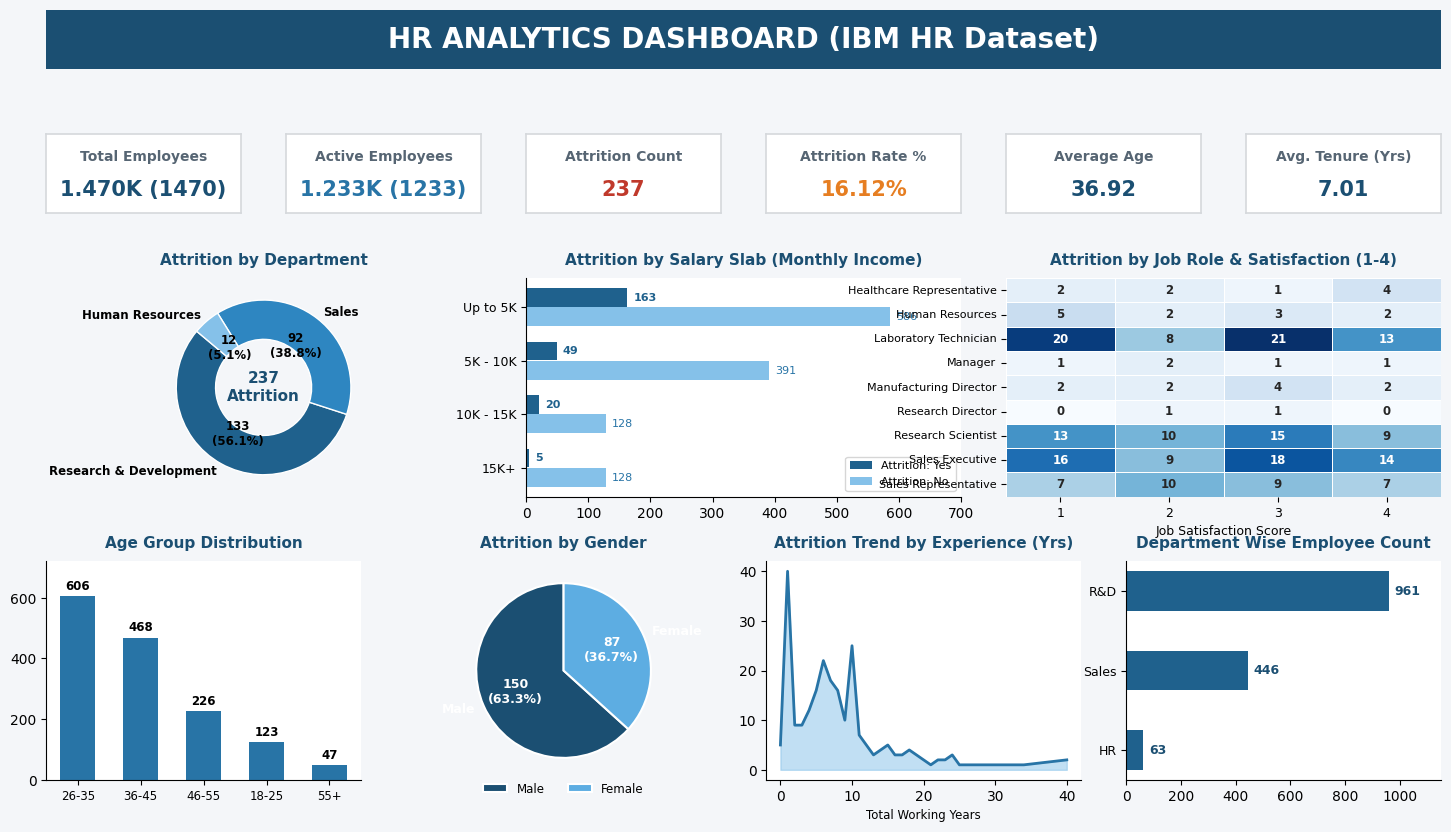

In [3]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as patches
import pandas as pd
import numpy as np

# Load and prepare data
df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')

# Derived columns
bins_age = [17, 25, 35, 45, 55, 100]
labels_age = ['18-25', '26-35', '36-45', '46-55', '55+']
df['AgeGroup'] = pd.cut(df['Age'], bins=bins_age, labels=labels_age)

bins_sal = [0, 5000, 10000, 15000, 25000]
labels_sal = ['Up to 5K', '5K - 10K', '10K - 15K', '15K+']
df['SalarySlab'] = pd.cut(df['MonthlyIncome'], bins=bins_sal, labels=labels_sal)

# Metrics
total_emp = len(df)
active_emp = (df['Attrition'] == 'No').sum()
attrition_cnt = (df['Attrition'] == 'Yes').sum()
attrition_rate = (attrition_cnt / total_emp) * 100
avg_age = df['Age'].mean()
avg_exp = df['YearsAtCompany'].mean() # 7.01 (or TotalWorkingYears = 11.28)

# Create Dashboard Image
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
fig = plt.figure(figsize=(18, 10), facecolor='#F4F6F9')
gs = gridspec.GridSpec(4, 12, figure=fig, height_ratios=[0.6, 0.8, 2.2, 2.2], hspace=0.45, wspace=0.6)

# 1. Header Banner
ax_header = fig.add_subplot(gs[0, :])
ax_header.set_facecolor('#1B4F72')
ax_header.text(0.5, 0.5, 'HR ANALYTICS DASHBOARD (IBM HR Dataset)', color='white', fontsize=20, fontweight='bold', ha='center', va='center')
ax_header.set_xticks([])
ax_header.set_yticks([])
for spine in ax_header.spines.values():
    spine.set_visible(False)

# 2. KPI Cards
kpis = [
    ("Total Employees", f"{total_emp/1000:.3f}K ({total_emp})", "#1B4F72"),
    ("Active Employees", f"{active_emp/1000:.3f}K ({active_emp})", "#2874A6"),
    ("Attrition Count", f"{attrition_cnt}", "#C0392B"),
    ("Attrition Rate %", f"{attrition_rate:.2f}%", "#E67E22"),
    ("Average Age", f"{avg_age:.2f}", "#1B4F72"),
    ("Avg. Tenure (Yrs)", f"{avg_exp:.2f}", "#1B4F72")
]

for i, (title, val, color) in enumerate(kpis):
    ax_kpi = fig.add_subplot(gs[1, i*2:(i+1)*2])
    ax_kpi.set_facecolor('white')
    ax_kpi.text(0.5, 0.72, title, color='#566573', fontsize=10, fontweight='bold', ha='center', va='center')
    ax_kpi.text(0.5, 0.30, val, color=color, fontsize=15, fontweight='bold', ha='center', va='center')
    ax_kpi.set_xticks([])
    ax_kpi.set_yticks([])
    for spine in ax_kpi.spines.values():
        spine.set_edgecolor('#D5D8DC')
        spine.set_linewidth(1.2)

# Filter for Attrition = Yes
att_df = df[df['Attrition'] == 'Yes']

# 3. Row 1 Charts: Attrition by Department (Donut), Attrition by Salary Slab (Bar), Attrition by Job Role & Satisfaction (Table/Heatmap)
# 3a. Attrition by Department
ax_dept = fig.add_subplot(gs[2, 0:4])
ax_dept.set_facecolor('white')
dept_att = att_df['Department'].value_counts()
colors_dept = ['#1F618D', '#2E86C1', '#85C1E9']
wedges, texts, autotexts = ax_dept.pie(
    dept_att, labels=dept_att.index, autopct=lambda p: f'{int(round(p*attrition_cnt/100))}\n({p:.1f}%)',
    startangle=140, colors=colors_dept, wedgeprops=dict(width=0.45, edgecolor='white'),
    textprops=dict(fontsize=8.5, fontweight='bold')
)
ax_dept.text(0, 0, f"{attrition_cnt}\nAttrition", ha='center', va='center', fontsize=11, fontweight='bold', color='#1B4F72')
ax_dept.set_title('Attrition by Department', fontsize=11, fontweight='bold', color='#1B4F72', pad=10)

# 3b. Attrition by Salary Slab
ax_sal = fig.add_subplot(gs[2, 4:8])
ax_sal.set_facecolor('white')
sal_ct = pd.crosstab(df['SalarySlab'], df['Attrition'])[['Yes', 'No']]
y_pos = np.arange(len(sal_ct.index))
ax_sal.barh(y_pos - 0.18, sal_ct['Yes'], height=0.35, label='Attrition: Yes', color='#1F618D')
ax_sal.barh(y_pos + 0.18, sal_ct['No'], height=0.35, label='Attrition: No', color='#85C1E9')
ax_sal.set_yticks(y_pos)
ax_sal.set_yticklabels(sal_ct.index, fontsize=9)
ax_sal.invert_yaxis()
ax_sal.set_title('Attrition by Salary Slab (Monthly Income)', fontsize=11, fontweight='bold', color='#1B4F72', pad=10)
ax_sal.legend(fontsize=8, loc='lower right')
for i, (v_yes, v_no) in enumerate(zip(sal_ct['Yes'], sal_ct['No'])):
    ax_sal.text(v_yes + 10, i - 0.18, str(v_yes), va='center', fontsize=8, fontweight='bold', color='#1F618D')
    ax_sal.text(v_no + 10, i + 0.18, str(v_no), va='center', fontsize=8, color='#2874A6')
ax_sal.set_xlim(0, 700)
ax_sal.spines['top'].set_visible(False)
ax_sal.spines['right'].set_visible(False)

# 3c. Attrition by Job Role & Job Satisfaction (Heatmap Matrix)
ax_mat = fig.add_subplot(gs[2, 8:12])
ax_mat.set_facecolor('white')
ct_js = pd.crosstab(att_df['JobRole'], att_df['JobSatisfaction'], margins=True, margins_name='Total')
sns.heatmap(ct_js.iloc[:-1, :-1], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax_mat, linewidths=0.5, annot_kws={"size": 8.5, "weight": "bold"})
ax_mat.set_title('Attrition by Job Role & Satisfaction (1-4)', fontsize=11, fontweight='bold', color='#1B4F72', pad=10)
ax_mat.set_xlabel('Job Satisfaction Score', fontsize=9)
ax_mat.set_ylabel('')
ax_mat.tick_params(axis='y', labelsize=8)
ax_mat.tick_params(axis='x', labelsize=9)

# 4. Row 2 Charts: Age Group Distribution, Attrition by Gender, Attrition Trend by Experience, Department Wise Headcount
# 4a. Age Group Distribution
ax_age = fig.add_subplot(gs[3, 0:3])
ax_age.set_facecolor('white')
age_cnt = df['AgeGroup'].value_counts()[['26-35', '36-45', '46-55', '18-25', '55+']]
bars = ax_age.bar(age_cnt.index, age_cnt.values, color='#2874A6', width=0.55)
ax_age.set_title('Age Group Distribution', fontsize=11, fontweight='bold', color='#1B4F72', pad=10)
for bar in bars:
    yval = bar.get_height()
    ax_age.text(bar.get_x() + bar.get_width()/2.0, yval + 12, int(yval), ha='center', va='bottom', fontsize=8.5, fontweight='bold')
ax_age.set_ylim(0, 720)
ax_age.spines['top'].set_visible(False)
ax_age.spines['right'].set_visible(False)
ax_age.tick_params(axis='x', labelsize=8.5)

# 4b. Attrition by Gender
ax_gen = fig.add_subplot(gs[3, 3:6])
ax_gen.set_facecolor('white')
gen_att = att_df['Gender'].value_counts()
ax_gen.pie(
    gen_att, labels=gen_att.index, autopct=lambda p: f'{int(round(p*attrition_cnt/100))}\n({p:.1f}%)',
    startangle=90, colors=['#1B4F72', '#5DADE2'], wedgeprops=dict(edgecolor='white', linewidth=1.5),
    textprops=dict(fontsize=9, fontweight='bold', color='white')
)
ax_gen.legend(gen_att.index, loc='lower center', bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8.5, frameon=False)
ax_gen.set_title('Attrition by Gender', fontsize=11, fontweight='bold', color='#1B4F72', pad=10)

# 4c. Attrition Trend by Experience (TotalWorkingYears)
ax_exp = fig.add_subplot(gs[3, 6:9])
ax_exp.set_facecolor('white')
exp_att = att_df['TotalWorkingYears'].value_counts().sort_index()
ax_exp.plot(exp_att.index, exp_att.values, color='#2874A6', linewidth=2)
ax_exp.fill_between(exp_att.index, exp_att.values, color='#85C1E9', alpha=0.5)
ax_exp.set_title('Attrition Trend by Experience (Yrs)', fontsize=11, fontweight='bold', color='#1B4F72', pad=10)
ax_exp.set_xlabel('Total Working Years', fontsize=8.5)
ax_exp.spines['top'].set_visible(False)
ax_exp.spines['right'].set_visible(False)

# 4d. Department Wise Employee Count
ax_demp = fig.add_subplot(gs[3, 9:12])
ax_demp.set_facecolor('white')
d_cnt = df['Department'].value_counts()
y_d = np.arange(len(d_cnt))
ax_demp.barh(y_d, d_cnt.values, color='#1F618D', height=0.5)
ax_demp.set_yticks(y_d)
ax_demp.set_yticklabels(['R&D', 'Sales', 'HR'], fontsize=9)
ax_demp.invert_yaxis()
ax_demp.set_title('Department Wise Employee Count', fontsize=11, fontweight='bold', color='#1B4F72', pad=10)
for i, v in enumerate(d_cnt.values):
    ax_demp.text(v + 20, i, str(v), va='center', fontsize=9, fontweight='bold', color='#1B4F72')
ax_demp.set_xlim(0, 1150)
ax_demp.spines['top'].set_visible(False)
ax_demp.spines['right'].set_visible(False)

plt.savefig('hr_analytics_dashboard_preview.png', dpi=150, bbox_inches='tight')
print("Saved dashboard preview successfully.")

Saved clean dashboard preview successfully.


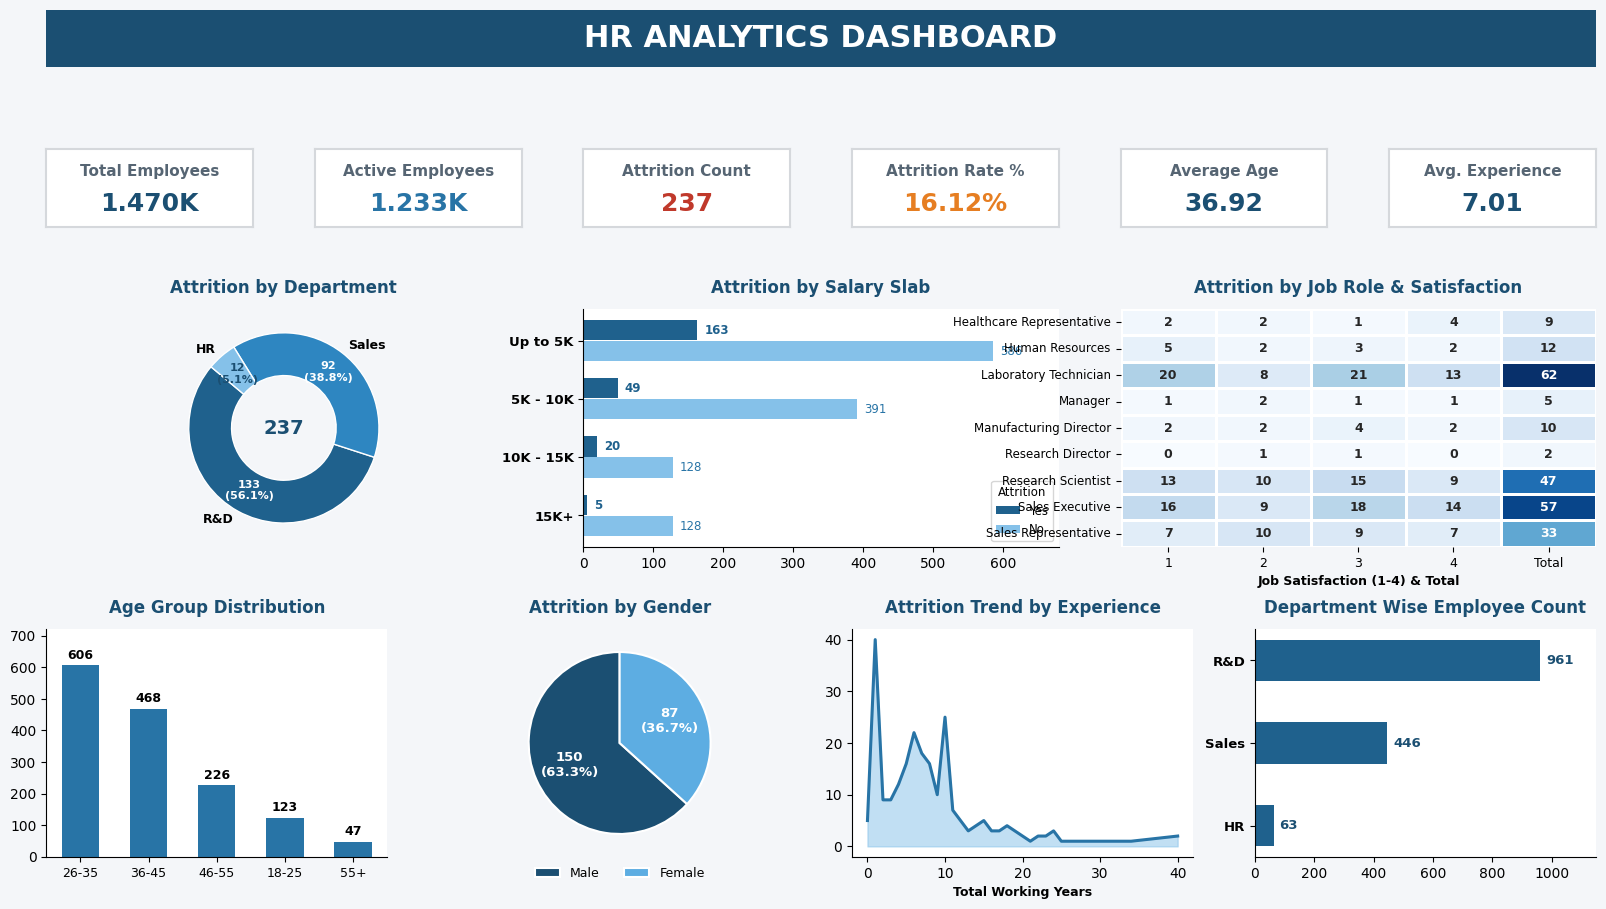

In [4]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
import seaborn as sns

df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')

bins_age = [17, 25, 35, 45, 55, 100]
labels_age = ['18-25', '26-35', '36-45', '46-55', '55+']
df['AgeGroup'] = pd.cut(df['Age'], bins=bins_age, labels=labels_age)

bins_sal = [0, 5000, 10000, 15000, 25000]
labels_sal = ['Up to 5K', '5K - 10K', '10K - 15K', '15K+']
df['SalarySlab'] = pd.cut(df['MonthlyIncome'], bins=bins_sal, labels=labels_sal)

total_emp = len(df)
active_emp = (df['Attrition'] == 'No').sum()
attrition_cnt = (df['Attrition'] == 'Yes').sum()
attrition_rate = (attrition_cnt / total_emp) * 100
avg_age = df['Age'].mean()
avg_exp = df['YearsAtCompany'].mean()

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
fig = plt.figure(figsize=(20, 11), facecolor='#F4F6F9')
gs = gridspec.GridSpec(4, 12, figure=fig, height_ratios=[0.55, 0.75, 2.3, 2.2], hspace=0.55, wspace=0.85)

# 1. Header Banner
ax_header = fig.add_subplot(gs[0, :])
ax_header.set_facecolor('#1B4F72')
ax_header.text(0.5, 0.5, 'HR ANALYTICS DASHBOARD', color='white', fontsize=22, fontweight='bold', ha='center', va='center')
ax_header.set_xticks([])
ax_header.set_yticks([])
for spine in ax_header.spines.values():
    spine.set_visible(False)

# 2. KPI Cards
kpis = [
    ("Total Employees", f"{total_emp/1000:.3f}K", "#1B4F72"),
    ("Active Employees", f"{active_emp/1000:.3f}K", "#2874A6"),
    ("Attrition Count", f"{attrition_cnt}", "#C0392B"),
    ("Attrition Rate %", f"{attrition_rate:.2f}%", "#E67E22"),
    ("Average Age", f"{avg_age:.2f}", "#1B4F72"),
    ("Avg. Experience", f"{avg_exp:.2f}", "#1B4F72")
]

for i, (title, val, color) in enumerate(kpis):
    ax_kpi = fig.add_subplot(gs[1, i*2:(i+1)*2])
    ax_kpi.set_facecolor('white')
    ax_kpi.text(0.5, 0.72, title, color='#566573', fontsize=11, fontweight='bold', ha='center', va='center')
    ax_kpi.text(0.5, 0.30, val, color=color, fontsize=18, fontweight='bold', ha='center', va='center')
    ax_kpi.set_xticks([])
    ax_kpi.set_yticks([])
    for spine in ax_kpi.spines.values():
        spine.set_edgecolor('#D5D8DC')
        spine.set_linewidth(1.5)

att_df = df[df['Attrition'] == 'Yes']

# 3a. Attrition by Department
ax_dept = fig.add_subplot(gs[2, 0:4])
ax_dept.set_facecolor('white')
dept_att = att_df['Department'].value_counts()
colors_dept = ['#1F618D', '#2E86C1', '#85C1E9']
wedges, texts, autotexts = ax_dept.pie(
    dept_att, labels=['R&D', 'Sales', 'HR'], autopct=lambda p: f'{int(round(p*attrition_cnt/100))}\n({p:.1f}%)',
    startangle=140, colors=colors_dept, wedgeprops=dict(width=0.45, edgecolor='white'),
    pctdistance=0.75, textprops=dict(fontsize=9, fontweight='bold')
)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(8)
autotexts[-1].set_color('#1B4F72')
ax_dept.text(0, 0, f"{attrition_cnt}", ha='center', va='center', fontsize=14, fontweight='bold', color='#1B4F72')
ax_dept.set_title('Attrition by Department', fontsize=12, fontweight='bold', color='#1B4F72', pad=12)

# 3b. Attrition by Salary Slab
ax_sal = fig.add_subplot(gs[2, 4:8])
ax_sal.set_facecolor('white')
sal_ct = pd.crosstab(df['SalarySlab'], df['Attrition'])[['Yes', 'No']]
y_pos = np.arange(len(sal_ct.index))
ax_sal.barh(y_pos - 0.18, sal_ct['Yes'], height=0.35, label='Yes', color='#1F618D')
ax_sal.barh(y_pos + 0.18, sal_ct['No'], height=0.35, label='No', color='#85C1E9')
ax_sal.set_yticks(y_pos)
ax_sal.set_yticklabels(sal_ct.index, fontsize=9.5, fontweight='bold')
ax_sal.invert_yaxis()
ax_sal.set_title('Attrition by Salary Slab', fontsize=12, fontweight='bold', color='#1B4F72', pad=12)
ax_sal.legend(title='Attrition', fontsize=8.5, title_fontsize=8.5, loc='lower right', frameon=True)
for i, (v_yes, v_no) in enumerate(zip(sal_ct['Yes'], sal_ct['No'])):
    ax_sal.text(v_yes + 10, i - 0.18, str(v_yes), va='center', fontsize=8.5, fontweight='bold', color='#1F618D')
    ax_sal.text(v_no + 10, i + 0.18, str(v_no), va='center', fontsize=8.5, color='#2874A6')
ax_sal.set_xlim(0, 680)
ax_sal.spines['top'].set_visible(False)
ax_sal.spines['right'].set_visible(False)

# 3c. Attrition by Job Role & Job Satisfaction
ax_mat = fig.add_subplot(gs[2, 8:12])
ax_mat.set_facecolor('white')
ct_js = pd.crosstab(att_df['JobRole'], att_df['JobSatisfaction'], margins=True, margins_name='Total')
sns.heatmap(ct_js.iloc[:-1, :], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax_mat, linewidths=0.8, annot_kws={"size": 9, "weight": "bold"})
ax_mat.set_title('Attrition by Job Role & Satisfaction', fontsize=12, fontweight='bold', color='#1B4F72', pad=12)
ax_mat.set_xlabel('Job Satisfaction (1-4) & Total', fontsize=9, fontweight='bold')
ax_mat.set_ylabel('')
ax_mat.tick_params(axis='y', labelsize=8.5)
ax_mat.tick_params(axis='x', labelsize=9)

# 4a. Age Group Distribution
ax_age = fig.add_subplot(gs[3, 0:3])
ax_age.set_facecolor('white')
age_cnt = df['AgeGroup'].value_counts()[['26-35', '36-45', '46-55', '18-25', '55+']]
bars = ax_age.bar(age_cnt.index, age_cnt.values, color='#2874A6', width=0.55)
ax_age.set_title('Age Group Distribution', fontsize=12, fontweight='bold', color='#1B4F72', pad=12)
for bar in bars:
    yval = bar.get_height()
    ax_age.text(bar.get_x() + bar.get_width()/2.0, yval + 12, int(yval), ha='center', va='bottom', fontsize=9, fontweight='bold')
ax_age.set_ylim(0, 720)
ax_age.spines['top'].set_visible(False)
ax_age.spines['right'].set_visible(False)
ax_age.tick_params(axis='x', labelsize=9)

# 4b. Attrition by Gender
ax_gen = fig.add_subplot(gs[3, 3:6])
ax_gen.set_facecolor('white')
gen_att = att_df['Gender'].value_counts()
wedges_g, texts_g, autotexts_g = ax_gen.pie(
    gen_att, autopct=lambda p: f'{int(round(p*attrition_cnt/100))}\n({p:.1f}%)',
    startangle=90, colors=['#1B4F72', '#5DADE2'], wedgeprops=dict(edgecolor='white', linewidth=1.5),
    textprops=dict(fontsize=9.5, fontweight='bold', color='white')
)
ax_gen.legend(gen_att.index, loc='lower center', bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=9, frameon=False)
ax_gen.set_title('Attrition by Gender', fontsize=12, fontweight='bold', color='#1B4F72', pad=12)

# 4c. Attrition Trend by Experience
ax_exp = fig.add_subplot(gs[3, 6:9])
ax_exp.set_facecolor('white')
exp_att = att_df['TotalWorkingYears'].value_counts().sort_index()
ax_exp.plot(exp_att.index, exp_att.values, color='#2874A6', linewidth=2.2)
ax_exp.fill_between(exp_att.index, exp_att.values, color='#85C1E9', alpha=0.5)
ax_exp.set_title('Attrition Trend by Experience', fontsize=12, fontweight='bold', color='#1B4F72', pad=12)
ax_exp.set_xlabel('Total Working Years', fontsize=9, fontweight='bold')
ax_exp.spines['top'].set_visible(False)
ax_exp.spines['right'].set_visible(False)

# 4d. Department Wise Employee Count
ax_demp = fig.add_subplot(gs[3, 9:12])
ax_demp.set_facecolor('white')
d_cnt = df['Department'].value_counts()
y_d = np.arange(len(d_cnt))
ax_demp.barh(y_d, d_cnt.values, color='#1F618D', height=0.5)
ax_demp.set_yticks(y_d)
ax_demp.set_yticklabels(['R&D', 'Sales', 'HR'], fontsize=9.5, fontweight='bold')
ax_demp.invert_yaxis()
ax_demp.set_title('Department Wise Employee Count', fontsize=12, fontweight='bold', color='#1B4F72', pad=12)
for i, v in enumerate(d_cnt.values):
    ax_demp.text(v + 20, i, str(v), va='center', fontsize=9.5, fontweight='bold', color='#1B4F72')
ax_demp.set_xlim(0, 1150)
ax_demp.spines['top'].set_visible(False)
ax_demp.spines['right'].set_visible(False)

plt.savefig('hr_analytics_dashboard_clean.png', dpi=150, bbox_inches='tight')
print("Saved clean dashboard preview successfully.")

Saved final dashboard successfully.


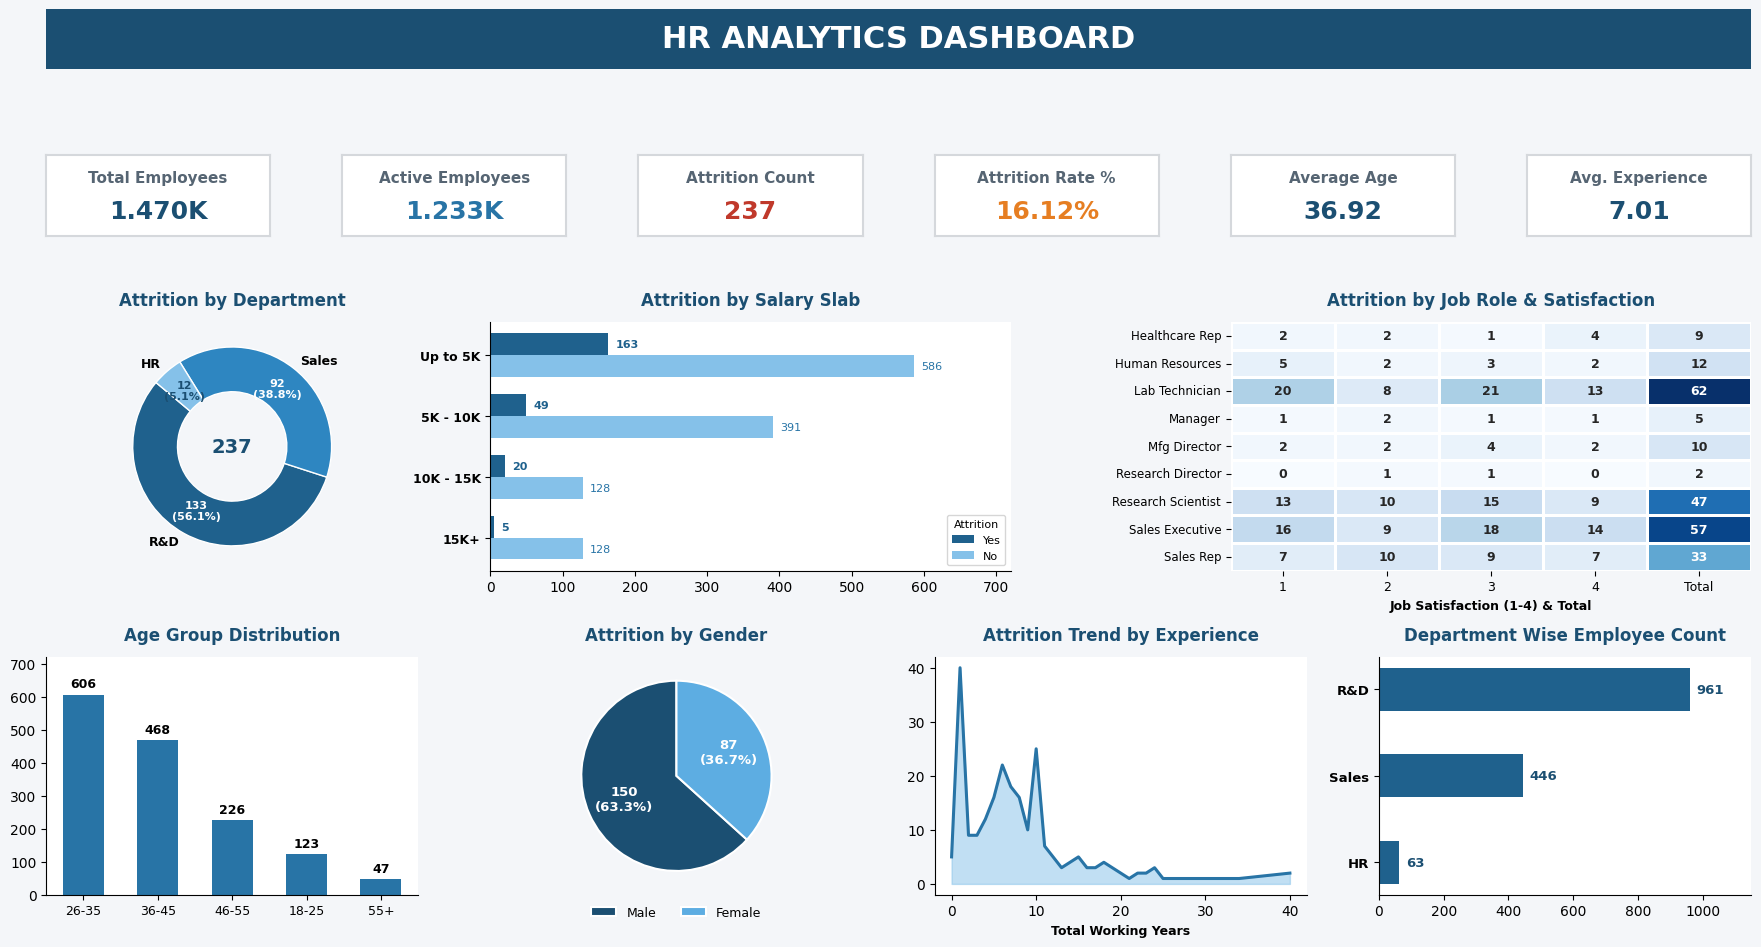

In [5]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
import seaborn as sns

df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')

bins_age = [17, 25, 35, 45, 55, 100]
labels_age = ['18-25', '26-35', '36-45', '46-55', '55+']
df['AgeGroup'] = pd.cut(df['Age'], bins=bins_age, labels=labels_age)

bins_sal = [0, 5000, 10000, 15000, 25000]
labels_sal = ['Up to 5K', '5K - 10K', '10K - 15K', '15K+']
df['SalarySlab'] = pd.cut(df['MonthlyIncome'], bins=bins_sal, labels=labels_sal)

total_emp = len(df)
active_emp = (df['Attrition'] == 'No').sum()
attrition_cnt = (df['Attrition'] == 'Yes').sum()
attrition_rate = (attrition_cnt / total_emp) * 100
avg_age = df['Age'].mean()
avg_exp = df['YearsAtCompany'].mean()

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
fig = plt.figure(figsize=(22, 11.5), facecolor='#F4F6F9')
gs = gridspec.GridSpec(4, 12, figure=fig, height_ratios=[0.55, 0.75, 2.3, 2.2], hspace=0.55, wspace=0.95)

# 1. Header Banner
ax_header = fig.add_subplot(gs[0, :])
ax_header.set_facecolor('#1B4F72')
ax_header.text(0.5, 0.5, 'HR ANALYTICS DASHBOARD', color='white', fontsize=22, fontweight='bold', ha='center', va='center')
ax_header.set_xticks([])
ax_header.set_yticks([])
for spine in ax_header.spines.values():
    spine.set_visible(False)

# 2. KPI Cards
kpis = [
    ("Total Employees", f"{total_emp/1000:.3f}K", "#1B4F72"),
    ("Active Employees", f"{active_emp/1000:.3f}K", "#2874A6"),
    ("Attrition Count", f"{attrition_cnt}", "#C0392B"),
    ("Attrition Rate %", f"{attrition_rate:.2f}%", "#E67E22"),
    ("Average Age", f"{avg_age:.2f}", "#1B4F72"),
    ("Avg. Experience", f"{avg_exp:.2f}", "#1B4F72")
]

for i, (title, val, color) in enumerate(kpis):
    ax_kpi = fig.add_subplot(gs[1, i*2:(i+1)*2])
    ax_kpi.set_facecolor('white')
    ax_kpi.text(0.5, 0.72, title, color='#566573', fontsize=11, fontweight='bold', ha='center', va='center')
    ax_kpi.text(0.5, 0.30, val, color=color, fontsize=18, fontweight='bold', ha='center', va='center')
    ax_kpi.set_xticks([])
    ax_kpi.set_yticks([])
    for spine in ax_kpi.spines.values():
        spine.set_edgecolor('#D5D8DC')
        spine.set_linewidth(1.5)

att_df = df[df['Attrition'] == 'Yes']

# 3a. Attrition by Department
ax_dept = fig.add_subplot(gs[2, 0:3])
ax_dept.set_facecolor('white')
dept_att = att_df['Department'].value_counts()
colors_dept = ['#1F618D', '#2E86C1', '#85C1E9']
wedges, texts, autotexts = ax_dept.pie(
    dept_att, labels=['R&D', 'Sales', 'HR'], autopct=lambda p: f'{int(round(p*attrition_cnt/100))}\n({p:.1f}%)',
    startangle=140, colors=colors_dept, wedgeprops=dict(width=0.45, edgecolor='white'),
    pctdistance=0.74, textprops=dict(fontsize=9, fontweight='bold')
)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(8)
autotexts[-1].set_color('#1B4F72')
ax_dept.text(0, 0, f"{attrition_cnt}", ha='center', va='center', fontsize=14, fontweight='bold', color='#1B4F72')
ax_dept.set_title('Attrition by Department', fontsize=12, fontweight='bold', color='#1B4F72', pad=12)

# 3b. Attrition by Salary Slab
ax_sal = fig.add_subplot(gs[2, 3:7])
ax_sal.set_facecolor('white')
sal_ct = pd.crosstab(df['SalarySlab'], df['Attrition'])[['Yes', 'No']]
y_pos = np.arange(len(sal_ct.index))
ax_sal.barh(y_pos - 0.18, sal_ct['Yes'], height=0.35, label='Yes', color='#1F618D')
ax_sal.barh(y_pos + 0.18, sal_ct['No'], height=0.35, label='No', color='#85C1E9')
ax_sal.set_yticks(y_pos)
ax_sal.set_yticklabels(sal_ct.index, fontsize=9, fontweight='bold')
ax_sal.invert_yaxis()
ax_sal.set_title('Attrition by Salary Slab', fontsize=12, fontweight='bold', color='#1B4F72', pad=12)
ax_sal.legend(title='Attrition', fontsize=8, title_fontsize=8, loc='lower right', frameon=True)
for i, (v_yes, v_no) in enumerate(zip(sal_ct['Yes'], sal_ct['No'])):
    ax_sal.text(v_yes + 10, i - 0.18, str(v_yes), va='center', fontsize=8, fontweight='bold', color='#1F618D')
    ax_sal.text(v_no + 10, i + 0.18, str(v_no), va='center', fontsize=8, color='#2874A6')
ax_sal.set_xlim(0, 720)
ax_sal.spines['top'].set_visible(False)
ax_sal.spines['right'].set_visible(False)

# 3c. Attrition by Job Role & Job Satisfaction
ax_mat = fig.add_subplot(gs[2, 8:12])
ax_mat.set_facecolor('white')
role_short = {
    'Healthcare Representative': 'Healthcare Rep',
    'Human Resources': 'Human Resources',
    'Laboratory Technician': 'Lab Technician',
    'Manager': 'Manager',
    'Manufacturing Director': 'Mfg Director',
    'Research Director': 'Research Director',
    'Research Scientist': 'Research Scientist',
    'Sales Executive': 'Sales Executive',
    'Sales Representative': 'Sales Rep'
}
att_df_copy = att_df.copy()
att_df_copy['JobRoleShort'] = att_df_copy['JobRole'].map(role_short)
ct_js = pd.crosstab(att_df_copy['JobRoleShort'], att_df_copy['JobSatisfaction'], margins=True, margins_name='Total')
sns.heatmap(ct_js.iloc[:-1, :], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax_mat, linewidths=0.8, annot_kws={"size": 9, "weight": "bold"})
ax_mat.set_title('Attrition by Job Role & Satisfaction', fontsize=12, fontweight='bold', color='#1B4F72', pad=12)
ax_mat.set_xlabel('Job Satisfaction (1-4) & Total', fontsize=9, fontweight='bold')
ax_mat.set_ylabel('')
ax_mat.tick_params(axis='y', labelsize=8.5, rotation=0)
ax_mat.tick_params(axis='x', labelsize=9)

# 4a. Age Group Distribution
ax_age = fig.add_subplot(gs[3, 0:3])
ax_age.set_facecolor('white')
age_cnt = df['AgeGroup'].value_counts()[['26-35', '36-45', '46-55', '18-25', '55+']]
bars = ax_age.bar(age_cnt.index, age_cnt.values, color='#2874A6', width=0.55)
ax_age.set_title('Age Group Distribution', fontsize=12, fontweight='bold', color='#1B4F72', pad=12)
for bar in bars:
    yval = bar.get_height()
    ax_age.text(bar.get_x() + bar.get_width()/2.0, yval + 12, int(yval), ha='center', va='bottom', fontsize=9, fontweight='bold')
ax_age.set_ylim(0, 720)
ax_age.spines['top'].set_visible(False)
ax_age.spines['right'].set_visible(False)
ax_age.tick_params(axis='x', labelsize=9)

# 4b. Attrition by Gender
ax_gen = fig.add_subplot(gs[3, 3:6])
ax_gen.set_facecolor('white')
gen_att = att_df['Gender'].value_counts()
wedges_g, texts_g, autotexts_g = ax_gen.pie(
    gen_att, autopct=lambda p: f'{int(round(p*attrition_cnt/100))}\n({p:.1f}%)',
    startangle=90, colors=['#1B4F72', '#5DADE2'], wedgeprops=dict(edgecolor='white', linewidth=1.5),
    textprops=dict(fontsize=9.5, fontweight='bold', color='white')
)
ax_gen.legend(gen_att.index, loc='lower center', bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=9, frameon=False)
ax_gen.set_title('Attrition by Gender', fontsize=12, fontweight='bold', color='#1B4F72', pad=12)

# 4c. Attrition Trend by Experience
ax_exp = fig.add_subplot(gs[3, 6:9])
ax_exp.set_facecolor('white')
exp_att = att_df['TotalWorkingYears'].value_counts().sort_index()
ax_exp.plot(exp_att.index, exp_att.values, color='#2874A6', linewidth=2.2)
ax_exp.fill_between(exp_att.index, exp_att.values, color='#85C1E9', alpha=0.5)
ax_exp.set_title('Attrition Trend by Experience', fontsize=12, fontweight='bold', color='#1B4F72', pad=12)
ax_exp.set_xlabel('Total Working Years', fontsize=9, fontweight='bold')
ax_exp.spines['top'].set_visible(False)
ax_exp.spines['right'].set_visible(False)

# 4d. Department Wise Employee Count
ax_demp = fig.add_subplot(gs[3, 9:12])
ax_demp.set_facecolor('white')
d_cnt = df['Department'].value_counts()
y_d = np.arange(len(d_cnt))
ax_demp.barh(y_d, d_cnt.values, color='#1F618D', height=0.5)
ax_demp.set_yticks(y_d)
ax_demp.set_yticklabels(['R&D', 'Sales', 'HR'], fontsize=9.5, fontweight='bold')
ax_demp.invert_yaxis()
ax_demp.set_title('Department Wise Employee Count', fontsize=12, fontweight='bold', color='#1B4F72', pad=12)
for i, v in enumerate(d_cnt.values):
    ax_demp.text(v + 20, i, str(v), va='center', fontsize=9.5, fontweight='bold', color='#1B4F72')
ax_demp.set_xlim(0, 1150)
ax_demp.spines['top'].set_visible(False)
ax_demp.spines['right'].set_visible(False)

plt.savefig('hr_analytics_dashboard_final.png', dpi=150, bbox_inches='tight')
print("Saved final dashboard successfully.")

In [8]:
!git config --global user.name "farrasfernandaa"

In [9]:
!git config --global user.email "farrasfernanda55@gmail.com"

In [10]:
!git clone https://github.com/farrasfernandaa/HR-ANALYTICS-DASHBOARD.git

Cloning into 'HR-ANALYTICS-DASHBOARD'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), done.


In [12]:
%cd HR-ANALYTICS-DASHBOARD

/content/HR-ANALYTICS-DASHBOARD
